# Task 1 (3 points)

Generate a toy dataset for the "XOR" problem:

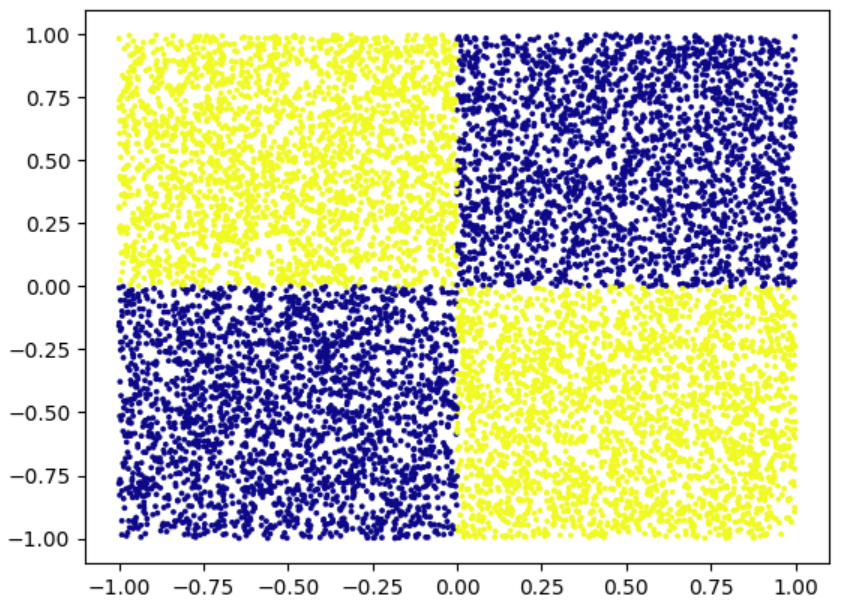

i.e. where the two features are distributed **uniformly** in $[-1, 1]$, and the target is $y = (x_0 >= 0) \text{ XOR } (x_1 >= 0)$.

Let the total number of points in the dataset be $N=10000$.

Fit a `sklearn.tree.DecisionTreeClassifier` on this data. Find a minimal `max_depth` value that results in train accuracy $>0.99$.

For each value of `max_depth` from 1 to the value found above, plot the data with the decision boundary for the obtained model. (*Hint: use `s=1` argument to `plt.scatter` to be able to see anything behind the data points.*)

For the model with train accuracy $>0.99$ use `sklearn.tree.plot_tree` to observe the tree structure.

Depth 1: train accuracy = 0.5135
Depth 2: train accuracy = 0.7588
Depth 3: train accuracy = 1.0000
Minimum max_depth: 3


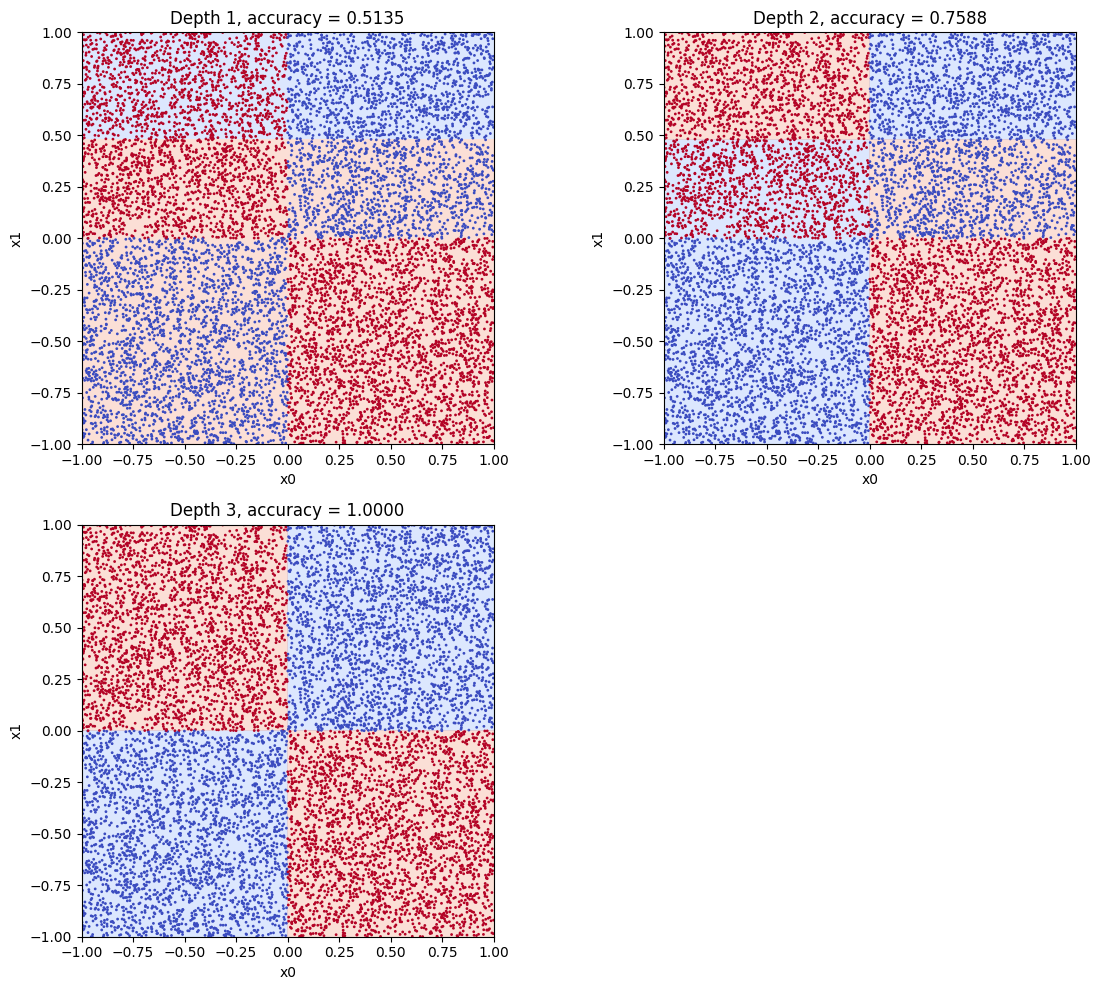

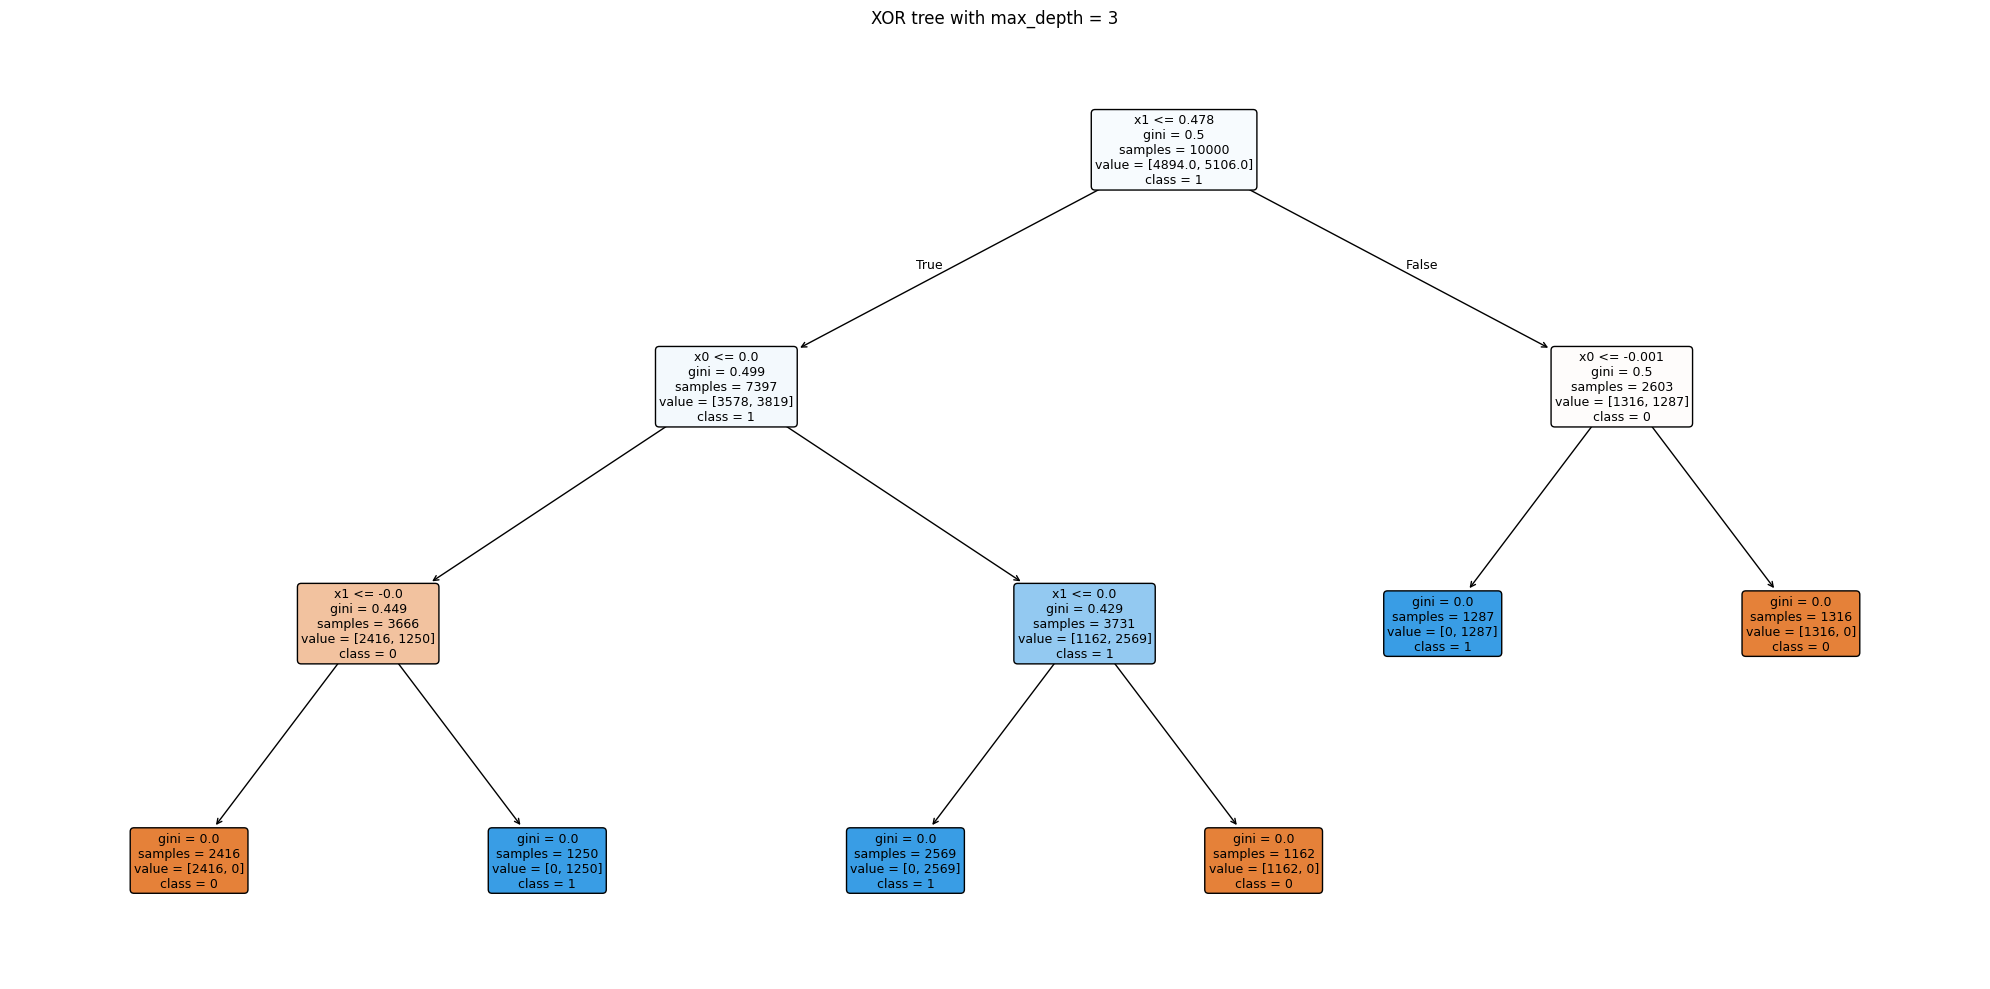

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Generated the XOR data with a fixed seed.
rng = np.random.default_rng(42)
N = 10000
X_xor = rng.uniform(-1, 1, size=(N, 2))
y_xor = (X_xor[:, 0] >= 0) ^ (X_xor[:, 1] >= 0)

# Increased the depth until training accuracy exceeded 0.99.
trees = []
train_scores = []
depth = 1
while True:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_xor, y_xor)
    score = accuracy_score(y_xor, tree.predict(X_xor))
    trees.append(tree)
    train_scores.append(score)
    print(f"Depth {depth}: train accuracy = {score:.4f}")
    if score > 0.99:
        break
    depth += 1

print("Minimum max_depth:", depth)

# Plotted the decision boundary for every tested depth.
xx, yy = np.meshgrid(np.linspace(-1, 1, 300), np.linspace(-1, 1, 300))
grid = np.column_stack([xx.ravel(), yy.ravel()])
fig, axes = plt.subplots((depth + 1) // 2, 2,
                         figsize=(12, 5 * ((depth + 1) // 2)), squeeze=False)
for i, tree in enumerate(trees):
    ax = axes.ravel()[i]
    labels = tree.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, labels, levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.3)
    ax.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=1)
    ax.set_title(f"Depth {i + 1}, accuracy = {train_scores[i]:.4f}")
    ax.set_xlabel("x0")
    ax.set_ylabel("x1")
    ax.set_aspect("equal")
for ax in axes.ravel()[depth:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

plt.figure(figsize=(20, 10))
plot_tree(trees[-1], feature_names=["x0", "x1"], class_names=["0", "1"],
          filled=True, rounded=True, fontsize=9)
plt.title(f"XOR tree with max_depth = {depth}")
plt.tight_layout()
plt.show()

# Task 2 (3 points)

Consider the following dataset:

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
print(data.DESCR)

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target_names[data.target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=12345)

print(X_train.iloc[:5])
print(y_train[:5])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

Build a `sklearn.tree.DecisionTreeClassifier` to maximize the test ROC AUC score.

When predicting cancer, it's much more dangerous to have a false negative prediction rather than false positive. Try to find the best tree (in terms of test ROC AUC) where the labels are re-weighted with the `class_weight={'malignant' : 2., 'benign' : 1.}` argument provided to the `DecisionTreeClassifier` constructor.

Plot test ROC curves for the two best models you found on the same plot.

        Model  Test ROC AUC criterion  max_depth  min_samples_leaf
Standard tree      0.962702      gini          3                20
Weighted tree      0.949169      gini          3                10


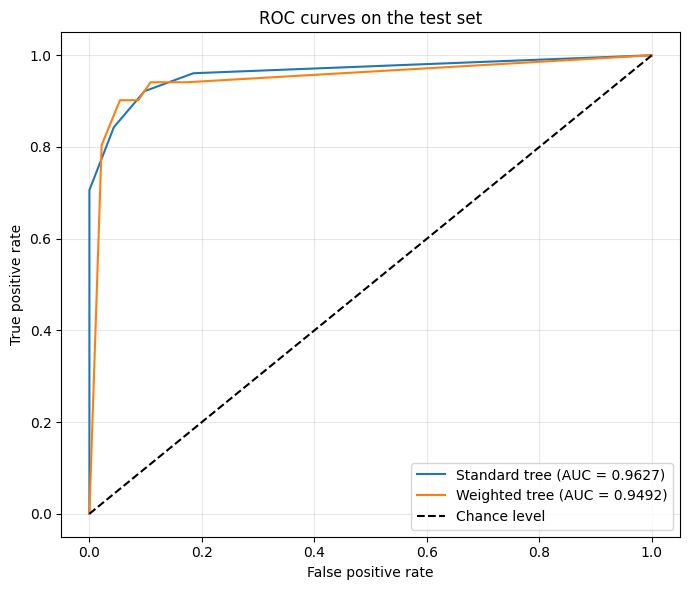

In [3]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import roc_auc_score, roc_curve

# Marked malignant tumors as the positive class.
y_test_binary = (y_test == "malignant").astype(int)
param_grid = {
    "max_depth": list(range(1, 11)) + [None],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "criterion": ["gini", "entropy"],
}
class_weights = {
    "Standard tree": None,
    "Weighted tree": {"malignant": 2., "benign": 1.},
}
best_models = {}
rows = []

# Compared the same parameter grid for both class-weight settings.
for name, weights in class_weights.items():
    best_auc = -1
    for params in ParameterGrid(param_grid):
        model = DecisionTreeClassifier(**params, class_weight=weights, random_state=42)
        model.fit(X_train, y_train)
        positive_column = list(model.classes_).index("malignant")
        probabilities = model.predict_proba(X_test)[:, positive_column]
        auc = roc_auc_score(y_test_binary, probabilities)
        if auc > best_auc:
            best_auc = auc
            best_model = model
            best_params = params.copy()

    best_models[name] = best_model
    rows.append({"Model": name, "Test ROC AUC": best_auc, **best_params})

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

# Plotted both ROC curves using malignant-class probabilities.
plt.figure(figsize=(7, 6))
for name, model in best_models.items():
    positive_column = list(model.classes_).index("malignant")
    probabilities = model.predict_proba(X_test)[:, positive_column]
    fpr, tpr, thresholds = roc_curve(y_test_binary, probabilities)
    auc = roc_auc_score(y_test_binary, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance level")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Short report

The XOR dataset contained 10,000 points with two uniform features in [-1, 1]. The first tested depth with training accuracy above 0.99 was **3**, with accuracy **1.0000**. The boundary plots showed how additional splits separated the XOR regions. The minimum depth described this generated sample and the fitted greedy trees.

For the cancer dataset, I kept the original train/test split and compared 110 parameter combinations for each class-weight setting. The best standard tree reached test ROC AUC **0.9627**, and the best weighted tree reached **0.9492**. I used the probability of the malignant class to calculate AUC and plot both ROC curves.

The weighted model gave malignant training examples twice the weight of benign examples. This did not guarantee fewer false negatives at a fixed prediction threshold. I selected both models by test ROC AUC, as requested in the task, so these scores were not independent estimates on unseen data. The selected models were the best within the tested grid.